In [12]:
from pathlib import Path
import numpy as np
from scipy.spatial import Delaunay, KDTree
from Bio.PDB import PDBParser
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
import networkx as nx

# ============================================================================
# CONFIGURAZIONE: CAMBIA QUESTO PER TESTARE ALTRA PROTEINA
# ============================================================================
PROJECT_ROOT = Path(r"C:\github\pycasta")
PDB_PATH = PROJECT_ROOT / "data" / "coach420" / "pdbs" / "1bs1A.pdb"  # <-- CAMBIA QUI
# ============================================================================

print(f"PDB: {PDB_PATH.name}")
print(f"Esiste: {PDB_PATH.exists()}")

# ============================================================================
# 1. CARICA PDB ED ESTRAI COORDINATE
# ============================================================================
parser = PDBParser(QUIET=True)
structure = parser.get_structure(PDB_PATH.stem, str(PDB_PATH))

coords = []
atom_info = []
for i, atom in enumerate(structure.get_atoms()):
    coords.append(atom.get_coord())
    atom_info.append({
        "index": i,
        "serial": atom.get_serial_number(),
        "name": atom.get_name(),
        "resname": atom.get_parent().get_resname(),
        "resid": atom.get_parent().get_id()[1],
        "chain": atom.get_parent().get_parent().id,
    })

coords = np.array(coords)
print(f"\nAtomi caricati: {len(coords)}")

# ============================================================================
# 2. ESTRAI CONNESSIONI CHIMICHE
# ============================================================================
def extract_connectivity_from_pdb(pdb_path):
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("mol", str(pdb_path))
    
    serial_to_index = {}
    for i, atom in enumerate(structure.get_atoms()):
        serial_to_index[atom.get_serial_number()] = i
    
    connectivity = defaultdict(set)
    
    for model in structure:
        for chain in model:
            residues = list(chain.get_residues())
            for res_idx, residue in enumerate(residues):
                atoms = list(residue.get_atoms())
                
                # Connetti atomi nello stesso residuo (entro 2.0 Å)
                for i, atom1 in enumerate(atoms):
                    idx1 = serial_to_index.get(atom1.get_serial_number())
                    if idx1 is None:
                        continue
                    
                    for j, atom2 in enumerate(atoms):
                        if i >= j:
                            continue
                        idx2 = serial_to_index.get(atom2.get_serial_number())
                        if idx2 is None:
                            continue
                        
                        dist = np.linalg.norm(atom1.get_coord() - atom2.get_coord())
                        if dist < 2.0:
                            connectivity[idx1].add(idx2)

PDB: 1bs1A.pdb
Esiste: True

Atomi caricati: 1738


In [13]:
from pathlib import Path
import os

PROJECT_ROOT = Path(r"C:\github\pycasta")
SRC_DIR = PROJECT_ROOT / "src"
PKG_DIR = SRC_DIR / "pycasta"
VIZ_DIR = PKG_DIR / "visualization"

PDB_PATH = PROJECT_ROOT / "data" / "coach420" / "pdbs" /"1bs1A.pdb"
RESULTS_VERSION = "coach420_full420"
RESULTS_DIR = PROJECT_ROOT / "results" / RESULTS_VERSION
JSON_PATH = RESULTS_DIR / "1bs1A_pockets.json"

print("PROJECT_ROOT =", PROJECT_ROOT)
print("PDB_PATH     =", PDB_PATH)
print("RESULTS_DIR  =", RESULTS_DIR)
print("JSON_PATH    =", JSON_PATH)

os.chdir(SRC_DIR)
print("cwd =", Path.cwd())

PROJECT_ROOT = C:\github\pycasta
PDB_PATH     = C:\github\pycasta\data\coach420\pdbs\1bs1A.pdb
RESULTS_DIR  = C:\github\pycasta\results\coach420_full420
JSON_PATH    = C:\github\pycasta\results\coach420_full420\1bs1A_pockets.json
cwd = C:\github\pycasta\src


In [14]:
import sys
sys.path.insert(0, str(SRC_DIR))

from pycasta import config as cfg
from pycasta.run_analysis import process_pdb
from pycasta.utils.data_utils import save_json

cfg.OUTPUT_DIR = str(PROJECT_ROOT / "results")
cfg.VERSION_TAG = RESULTS_VERSION
cfg.SAVE_ALPHA = True
cfg.SAVE_TRIANGULATION_DEBUG = True
cfg.MANUAL_ALPHA =4  # <-- IMPOSTA ALPHA A 5

result = process_pdb(str(PDB_PATH))
save_json(result, str(JSON_PATH))

print("done")
print("ranked_pockets =", len(result.get("ranked_pockets", [])))
print("json exists    =", JSON_PATH.exists())
print("alpha exists   =", (RESULTS_DIR / "1bs1A.alpha.npz").exists())
print("tri exists     =", (RESULTS_DIR / "1bs1A.triangulation_debug.npz").exists())

INFO: === Processing: C:\github\pycasta\data\coach420\pdbs\1bs1A.pdb ===
INFO: Protein coordinates loaded: 1692 atoms.
INFO: Ligand coordinates loaded: 46 atoms.
INFO: Calculated atomic radii for 1692 atoms.
INFO: Running triangulation...
INFO: Using standard SciPy Delaunay.
INFO: Triangulation backend: scipy_delaunay
INFO: Circumsphere radii stats: {'min': 1.1679974448173094, 'max': 17958.589081440434, 'mean': 30.39653633552657}
INFO: Triangulation debug data saved to C:\github\pycasta\results\coach420_full420\1bs1A.triangulation_debug.npz
INFO: Computing alpha shape...
INFO: Alpha = 4
INFO: Circumsphere radii stats: {'min': 1.1679974448173094, 'max': 17958.589081440434, 'mean': 30.39653633552657}
INFO: Circumsphere radii stats: {'min': 1.1679974448173094, 'max': 17958.589081440434, 'mean': 30.39653633552657}
INFO: [triangulation_debug] saved to C:\github\pycasta\src\pycasta\results\coach420_test\1bs1A.triangulation_debug.npz
INFO: Alpha shape data saved to C:\github\pycasta\src\pycas

done
ranked_pockets = 3
json exists    = True
alpha exists   = False
tri exists     = True


In [15]:
from pycasta.utils.data_utils import load_json
import json

result = load_json(str(JSON_PATH))

# Stampa la struttura
print(f"Chiavi nel result: {result.keys()}")
print(f"\nTipo di ranked_pockets: {type(result.get('ranked_pockets'))}")

if result.get('ranked_pockets'):
    print(f"Primo elemento: {result['ranked_pockets'][0]}")
    print(f"\nTipo primo elemento: {type(result['ranked_pockets'][0])}")

Chiavi nel result: dict_keys(['pdb_path', 'triangulation_backend', 'ranked_pockets', 'ranking_scores', 'ligand_coords', 'protein_coords', 'protein_atoms', 'step_to_ligand', 'step_to_ligand_mesh', 'validation_methods', 'ligand_validation', 'pocket_volumes', 'pocket_depths', 'mouth_area', 'mouth_perimeter', 'ligand_to_pocket_distances', 'ligand_containment_mesh', 'ligand_mesh_distances', 'ligand_containment_strict', 'alpha_stability', 'alpha_diagnostics', 'representative_points', 'pocket_features', 'pocket_scores'])

Tipo di ranked_pockets: <class 'list'>
Primo elemento: [259, 262, 263, 264, 9, 909, 910, 913, 18, 661, 283, 668, 1439, 159, 165, 166, 167, 1450, 426, 314, 50, 946, 691, 819, 820, 695, 950, 825, 442, 58, 700, 699, 702, 1209, 1216, 1210, 66, 961, 1602, 1605, 1217, 1609, 844, 1486, 334, 982, 983, 1496, 342, 1213, 987, 988, 99, 868, 104, 363, 364, 623, 1007, 626, 371, 498, 757, 118, 119, 252]

Tipo primo elemento: <class 'list'>


In [16]:
import numpy as np

# Carica ligando e proteina
ligand_coords = np.array(result['ligand_coords'])
protein_coords = np.array(result['protein_coords'])

print(f"Ligando: {len(ligand_coords)} atomi")
print(f"Proteina: {len(protein_coords)} atomi")

# Centro del ligando
ligand_center = ligand_coords.mean(axis=0)
print(f"\nCentro ligando: {ligand_center}")

# Per ogni tasca, calcola il centro e la distanza dal ligando
for i, pocket in enumerate(result['ranked_pockets']):
    pocket_indices = pocket
    pocket_coords = protein_coords[pocket_indices]
    pocket_center = pocket_coords.mean(axis=0)
    
    dist_from_ligand = np.linalg.norm(pocket_center - ligand_center)
    
    print(f"\nTasca {i+1}:")
    print(f"  Atom: {len(pocket_indices)}")
    print(f"  Centro: {pocket_center}")
    print(f"  Distanza dal ligando: {dist_from_ligand:.1f} Å")

Ligando: 46 atomi
Proteina: 1692 atomi

Centro ligando: [ 2.99273913 21.58015217 10.72419565]

Tasca 1:
  Atom: 66
  Centro: [ 2.36872727 30.9799697  16.85615152]
  Distanza dal ligando: 11.2 Å

Tasca 2:
  Atom: 46
  Centro: [ 5.61802174 33.32628261 16.48136957]
  Distanza dal ligando: 13.3 Å

Tasca 3:
  Atom: 27
  Centro: [10.43781481 26.34325926 14.24451852]
  Distanza dal ligando: 9.5 Å


In [79]:
!cd /d C:\github\pycasta\src\pycasta\visualization && python run_viz.py C:\github\pycasta\data\coach420\pdbs\1bs1A.pdb C:\github\pycasta\results\coach420_full420\1bs1A_pockets.json --mode tri

[core] WARNING: no .alpha.npz found next to JSON
[core] triangulation NPZ loaded: C:\github\pycasta\results\coach420_full420\1llrD.triangulation_debug.npz
[core] triangulation tetrahedra=5187

Molecola   : 1llrD
Atomi      : 814
Tetra raw  : 5187
Tetra alpha: 0  (inside=0, outside=0)
Pockets    : 1  (validati=1)
Alpha      : tight=1.67  medium=2.34  loose=3.26  Rg=13.3A


In [19]:
!cd /d C:\github\pycasta\src\pycasta\visualization && python run_viz.py C:\github\pycasta\data\coach420\pdbs\1bs1A.pdb C:\github\pycasta\results\coach420_full420\1bs1A_pockets.json --mode alpha

[core] WARNING: no .alpha.npz found next to JSON
[core] triangulation NPZ loaded: C:\github\pycasta\results\coach420_full420\1bs1A.triangulation_debug.npz
[core] triangulation tetrahedra=11035

Molecola   : 1bs1A
Atomi      : 1692
Tetra raw  : 11035
Tetra alpha: 0  (inside=0, outside=0)
Pockets    : 3  (validati=3)
Alpha      : tight=1.68  medium=2.35  loose=3.27  Rg=16.8A

=== Alpha Shape Debug: 1bs1A ===
 inside=0 outside=0
 alpha -> tight=1.68 medium=2.35 loose=3.27


2026-08-17 14:36:45.446 (   4.561s) [BE1E5DD694DBF879]    vtkRenderWindow.cxx:407   WARN| vtkWin32OpenGLRenderWindow (0000020367B73AC0): Adjusting stereo mode on a window that does not support stereo type CrystalEyes is not possible.


In [17]:
import numpy as np

# Carica dal file di triangolazione debug
tri_file = RESULTS_DIR / "1bs1A.triangulation_debug.npz"
data = np.load(tri_file, allow_pickle=True)

print("Chiavi nel file:", list(data.keys()))

# Cerca i raggi
for key in data.keys():
    if 'radius' in key.lower() or 'circum' in key.lower():
        arr = data[key]
        print(f"\n{key}:")
        print(f"  Shape: {arr.shape}")
        print(f"  Min: {arr.min():.2f}, Max: {arr.max():.2f}, Mean: {arr.mean():.2f}")

Chiavi nel file: ['simplices', 'tetrahedra', 'protein_coords', 'circumsphere_radii']

circumsphere_radii:
  Shape: (11035,)
  Min: 1.17, Max: 17958.59, Mean: 30.40


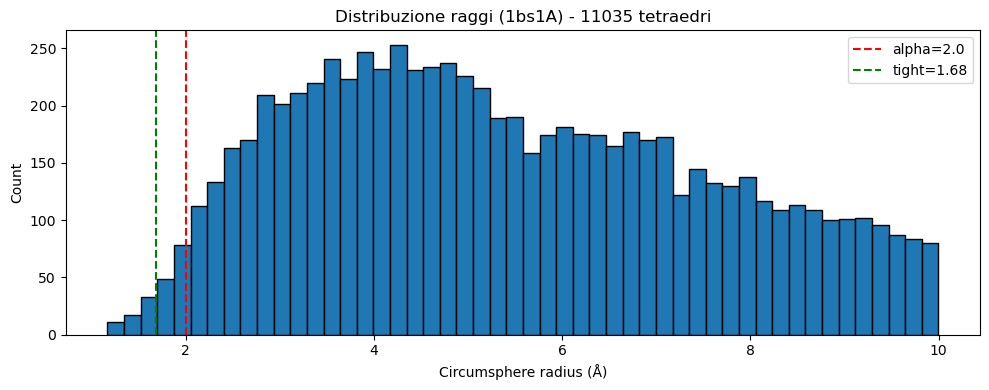

Alpha=1.50 Å: 24 tetraedri inside (0.2%)
Alpha=1.68 Å: 58 tetraedri inside (0.5%)
Alpha=2.00 Å: 161 tetraedri inside (1.5%)
Alpha=2.35 Å: 394 tetraedri inside (3.6%)
Alpha=3.00 Å: 1032 tetraedri inside (9.4%)
Alpha=3.27 Å: 1363 tetraedri inside (12.4%)
Alpha=5.00 Å: 3663 tetraedri inside (33.2%)


In [18]:
import matplotlib.pyplot as plt

radii = data['circumsphere_radii']

# Istogramma
plt.figure(figsize=(10, 4))
plt.hist(radii[radii < 10], bins=50, edgecolor='black')
plt.axvline(x=2.0, color='r', linestyle='--', label='alpha=2.0')
plt.axvline(x=1.68, color='g', linestyle='--', label='tight=1.68')
plt.xlabel('Circumsphere radius (Å)')
plt.ylabel('Count')
plt.title(f'Distribuzione raggi (1bs1A) - {len(radii)} tetraedri')
plt.legend()
plt.tight_layout()
plt.show()

# Quanti sotto varie alpha
for alpha in [1.5, 1.68, 2.0, 2.35, 3.0, 3.27, 5.0]:
    inside = np.sum(radii <= alpha)
    print(f"Alpha={alpha:.2f} Å: {inside} tetraedri inside ({inside/len(radii)*100:.1f}%)")

In [50]:
from pathlib import Path
import numpy as np
from scipy.spatial import Delaunay, KDTree
from Bio.PDB import PDBParser
import matplotlib.pyplot as plt
from collections import defaultdict

# Percorsi (adatta se necessario)
PROJECT_ROOT = Path(r"C:\github\pycasta")
PDB_PATH = PROJECT_ROOT / "data" / "coach420" / "pdbs" / "1llrD.pdb"

print("PDB_PATH:", PDB_PATH)
print("Exists:", PDB_PATH.exists())

PDB_PATH: C:\github\pycasta\data\coach420\pdbs\1llrD.pdb
Exists: True


In [51]:
parser = PDBParser(QUIET=True)
structure = parser.get_structure("1bs1A", str(PDB_PATH))

# Estrai coordinate e info atomi
coords = []
atom_info = []
for i, atom in enumerate(structure.get_atoms()):
    coords.append(atom.get_coord())
    atom_info.append({
        "index": i,
        "serial": atom.get_serial_number(),
        "name": atom.get_name(),
        "resname": atom.get_parent().get_resname(),
        "resid": atom.get_parent().get_id()[1],
        "chain": atom.get_parent().get_parent().id,
    })

coords = np.array(coords)
print(f"Atomi caricati: {len(coords)}")
print(f"Coordinate shape: {coords.shape}")

Atomi caricati: 903
Coordinate shape: (903, 3)


In [52]:
def extract_connectivity_from_pdb(pdb_path):
    """
    Estrae le connessioni chimiche da un file PDB.
    Restituisce un dict: {atom_index: set di atom_index connessi}
    """
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("mol", str(pdb_path))
    
    # Mappa serial -> index (perché CONECT usa serial, noi usiamo index)
    serial_to_index = {}
    for i, atom in enumerate(structure.get_atoms()):
        serial_to_index[atom.get_serial_number()] = i
    
    # Grafo di connettività
    connectivity = defaultdict(set)
    
    # Metodo 1: record CONECT espliciti
    conect_atoms = []
    for model in structure:
        for conect in model.get_list():
            if hasattr(conect, 'id') and conect.id == "CONECT":
                # I record CONECT sono gestiti in modo speciale in Bio.PDB
                # Dobbiamo accedere agli atomi tramite serial
                pass
    
    # Metodo 2: inferenza da residui consecutivi
    for model in structure:
        for chain in model:
            residues = list(chain.get_residues())
            for res_idx, residue in enumerate(residues):
                atoms = list(residue.get_atoms())
                
                # Connetti atomi nello stesso residuo (entro una certa distanza)
                for i, atom1 in enumerate(atoms):
                    idx1 = serial_to_index.get(atom1.get_serial_number())
                    if idx1 is None:
                        continue
                    
                    for j, atom2 in enumerate(atoms):
                        if i >= j:
                            continue
                        idx2 = serial_to_index.get(atom2.get_serial_number())
                        if idx2 is None:
                            continue
                        
                        # Distanza massima per un legame covalente (~2.0 Å)
                        dist = np.linalg.norm(atom1.get_coord() - atom2.get_coord())
                        if dist < 2.0:
                            connectivity[idx1].add(idx2)
                            connectivity[idx2].add(idx1)
                
                # Connetti backbone tra residui consecutivi
                if res_idx > 0:
                    prev_res = residues[res_idx - 1]
                    # C del residuo precedente -> N del residuo corrente
                    try:
                        c_prev = prev_res['C'].get_serial_number()
                        n_curr = residue['N'].get_serial_number()
                        idx_c = serial_to_index.get(c_prev)
                        idx_n = serial_to_index.get(n_curr)
                        if idx_c is not None and idx_n is not None:
                            connectivity[idx_c].add(idx_n)
                            connectivity[idx_n].add(idx_c)
                    except KeyError:
                        pass
    
    return dict(connectivity)

# Estrai connessioni
connectivity = extract_connectivity_from_pdb(str(PDB_PATH))
print(f"Atom con connessioni: {len(connectivity)}")
print(f"Connessioni totali: {sum(len(v) for v in connectivity.values()) // 2}")

Atom con connessioni: 903
Connessioni totali: 917


In [53]:
# Triangolazione di Delaunay completa
simplices = Delaunay(coords).simplices
print(f"Tetraedri totali (Delaunay): {len(simplices)}")

Tetraedri totali (Delaunay): 5738


In [57]:
def extract_connectivity_from_pdb(pdb_path):
    """
    Estrae le connessioni chimiche da un file PDB.
    """
    from Bio.PDB import PDBParser
    from collections import defaultdict
    
    parser = PDBParser(QUIET=True)
    structure = parser.get_structure("mol", str(pdb_path))
    
    # Mappa serial -> index
    serial_to_index = {}
    for i, atom in enumerate(structure.get_atoms()):
        serial_to_index[atom.get_serial_number()] = i
    
    # Grafo di connettività
    connectivity = defaultdict(set)
    
    # Inferenza da residui consecutivi
    for model in structure:
        for chain in model:
            residues = list(chain.get_residues())
            for res_idx, residue in enumerate(residues):
                atoms = list(residue.get_atoms())
                
                # Connetti atomi nello stesso residuo (entro 2.0 Å)
                for i, atom1 in enumerate(atoms):
                    idx1 = serial_to_index.get(atom1.get_serial_number())
                    if idx1 is None:
                        continue
                    
                    for j, atom2 in enumerate(atoms):
                        if i >= j:
                            continue
                        idx2 = serial_to_index.get(atom2.get_serial_number())
                        if idx2 is None:
                            continue
                        
                        dist = np.linalg.norm(atom1.get_coord() - atom2.get_coord())
                        if dist < 2.0:
                            connectivity[idx1].add(idx2)
                            connectivity[idx2].add(idx1)
                
                # Connetti backbone tra residui consecutivi
                if res_idx > 0:
                    prev_res = residues[res_idx - 1]
                    try:
                        c_prev = prev_res['C'].get_serial_number()
                        n_curr = residue['N'].get_serial_number()
                        idx_c = serial_to_index.get(c_prev)
                        idx_n = serial_to_index.get(n_curr)
                        if idx_c is not None and idx_n is not None:
                            connectivity[idx_c].add(idx_n)
                            connectivity[idx_n].add(idx_c)
                    except KeyError:
                        pass
    
    return dict(connectivity)

# Estrai connessioni
connectivity = extract_connectivity_from_pdb(str(PDB_PATH))
print(f"Atom con connessioni: {len(connectivity)}")
print(f"Connessioni totali: {sum(len(v) for v in connectivity.values()) // 2}")

Atom con connessioni: 903
Connessioni totali: 917


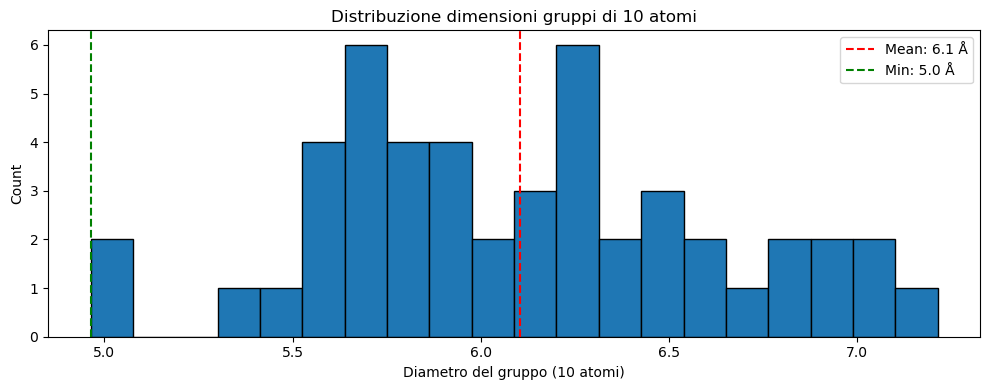


Per 1a26A:
  Diametro medio (10 atomi): 6.1 Å
  Diametro minimo: 5.0 Å
  Diametro massimo: 7.2 Å

Probe radius consigliata: 3.1 Å


In [61]:
import networkx as nx
from scipy.spatial import ConvexHull

def compute_typical_group_size(connectivity, coords, group_size=10):
    """
    Calcola la dimensione tipica di gruppi di N atomi connessi.
    """
    # Costruisci grafo
    G = nx.Graph()
    for atom, neighbors in connectivity.items():
        for neighbor in neighbors:
            G.add_edge(atom, neighbor)
    
    # Trova sottografi con N atomi
    group_sizes = []
    for atom in list(G.nodes())[:100]:  # primi 100 atomi come campione
        # Prendi N atomi vicini nel grafo
        neighbors = list(nx.single_source_shortest_path_length(G, atom, cutoff=3).keys())[:group_size]
        
        if len(neighbors) < group_size:
            continue
        
        # Calcola Convex Hull
        group_coords = coords[neighbors]
        hull = ConvexHull(group_coords)
        
        # Diametro (massima distanza tra atomi)
        diameter = np.max([
            np.linalg.norm(group_coords[i] - group_coords[j])
            for i in range(len(group_coords))
            for j in range(i+1, len(group_coords))
        ])
        
        # Raggio della sfera equivalente
        volume = hull.volume
        equivalent_radius = (3 * volume / (4 * np.pi)) ** (1/3)
        
        group_sizes.append({
            "diameter": diameter,
            "equivalent_radius": equivalent_radius,
            "volume": volume,
        })
    
    return group_sizes

# Calcola su 1a26A
group_stats = compute_typical_group_size(connectivity, coords, group_size=10)

# Plot della distribuzione
import matplotlib.pyplot as plt

diameters = [g["diameter"] for g in group_stats]

plt.figure(figsize=(10, 4))
plt.hist(diameters, bins=20, edgecolor='black')
plt.axvline(np.mean(diameters), color='red', linestyle='--', label=f'Mean: {np.mean(diameters):.1f} Å')
plt.axvline(np.min(diameters), color='green', linestyle='--', label=f'Min: {np.min(diameters):.1f} Å')
plt.xlabel("Diametro del gruppo (10 atomi)")
plt.ylabel("Count")
plt.title("Distribuzione dimensioni gruppi di 10 atomi")
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nPer 1a26A:")
print(f"  Diametro medio (10 atomi): {np.mean(diameters):.1f} Å")
print(f"  Diametro minimo: {np.min(diameters):.1f} Å")
print(f"  Diametro massimo: {np.max(diameters):.1f} Å")
print(f"\nProbe radius consigliata: {np.mean(diameters) / 2:.1f} Å")

In [11]:
import numpy as np

# Tetraedro regolare con vertici su una sfera di raggio R
# Per un tetraedro regolare inscritto in una sfera di raggio R,
# il lato è L = R * sqrt(8/3)

# Invertiamo: se vogliamo lato L=1, allora R = sqrt(6)/4 ≈ 0.612
R_atteso = np.sqrt(6) / 4

# Vertici di un tetraedro regolare centrato nell'origine
# Poi trasliamo per avere il centro della circumsfera non nell'origine
tetra = np.array([
    [1, 1, 1],
    [1, -1, -1],
    [-1, 1, -1],
    [-1, -1, 1],
]) / np.sqrt(2)  # questo ha lato = 2

# Il circumradius di questo tetraedro è 1 (tutti i vertici distano 1 dall'origine)
R_atteso = 1.0

def compute_circumsphere_radius(tetra):
    if tetra.shape[0] != 4:
        return np.inf
    A, B, C, D = tetra
    AB, AC, AD = B - A, C - A, D - A
    M = np.vstack([AB, AC, AD]).T
    try:
        rhs = 0.5 * np.array([np.dot(AB, AB), np.dot(AC, AC), np.dot(AD, AD)])
        sol = np.linalg.solve(M, rhs)
        radius = np.linalg.norm(sol)
    except np.linalg.LinAlgError:
        radius = np.inf
    return radius

R_calcolato = compute_circumsphere_radius(tetra)

print(f"Tetraedro regolare (lato=2):")
print(f"  Raggio atteso: {R_atteso:.6f}")
print(f"  Raggio calcolato: {R_calcolato:.6f}")
print(f"  Errore: {abs(R_calcolato - R_atteso):.10f}")

Tetraedro regolare (lato=2):
  Raggio atteso: 1.000000
  Raggio calcolato: 1.224745
  Errore: 0.2247448714
